# DATA - Overview + Prep (vector)
|Data |Description|Preprocess|
|------|------------|-----|
|Air Pollution|NO2 Council sensor data (pdf)|<ul><li>Clean csvs from pdf</li><li>**Join** with sensor info</li><li>Make gdf</li></ul>| 
|Greenspaces|Council Trees(csv, shp)|<ul><li>Clean columns</li></ul>|
|Greensapces|OS Open Greenspaces (shp) | <ul><li>Clip to Edi</li><li>Clean cols</li></ul>|
|Traffic|Dft AADF(csv) + OS Open Roads(shp)| <ul><li>Clean cols</li><li>**Join** with OS roads</li></ul>|


Other data:
* Edinburgh boundary polygon

In [1]:
# Base filepath!! 
base = '/home/s2975916/cgp/'

# Import necessary libraries
import pandas as pd
import geopandas as gpd
import folium

import os
import zipfile
from pathlib import Path

import heapq
import math
from collections import defaultdict
from shapely.geometry import Point

In [97]:
# Pull directly from oracle???
import oracledb
import getpass

username='s2975916' 
password = getpass.getpass("Oracle password: ")

dsn = """
(DESCRIPTION=
    (ADDRESS=(PROTOCOL=TCP)(HOST=ora-geoslrn-kb1live.is.ed.ac.uk)(PORT=1842))
    (ADDRESS=(PROTOCOL=TCP)(HOST=ora-geoslrn-at1live.is.ed.ac.uk)(PORT=1842))
    (CONNECT_DATA=
        (SERVER=DEDICATED)
        (SERVICE_NAME=GLRNLIVE_PRMY.is.ed.ac.uk)
    )
)
"""

conn = oracledb.connect(
    user=username,
    password=password,
    dsn=dsn)

print("Connected successfully!")

DatabaseError: ORA-01017: invalid username/password; logon denied
Help: https://docs.oracle.com/error-help/db/ora-01017/

In [ ]:
import pandas as pd

tables = pd.read_sql(
    "SELECT table_name FROM user_tables",
    con=conn)

print(tables)

                        TABLE_NAME
0                        MSC_CLASS
1       CGP_POLLUTION_SITE_DETAILS
2                          TRAFFIC
3         CGP_POLLUTION_ANNUAL_NO2
4                      CGP_TRAFFIC
5     CGP_POLLUTION_NO2_CITYCENTRE
6     CGP_POLLUTION_NO2_GLASGOW_RD
7         CGP_POLLUTION_STJOHNS_RD
8   CGP_POLLUTION_NO2_GREATJUNC_ST
9                     CGP_OS_GREEN
10                    CGP_OS_ROADS
11               CGP_COUNCIL_TREES
12                      MY_FRIENDS


/tmp/ipykernel_2872571/2929828769.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  tables = pd.read_sql(


Load in spatial datasets needed to pre-process: Edinburgh council boundary 
* To clip Ordinance Survey data to (OS Greenspaces, OS Roads)

In [105]:
# Load in edinburgh boundary shapefil
edi_boundary_path = os.path.join(base, 'data/raw/Community_Council_Boundaries_(from_28_March_2025)/Community_Council_Boundaries_(from_28_March_2025).shp')
edi_boundary_gdf = gpd.read_file(edi_boundary_path)

<AxesSubplot: >

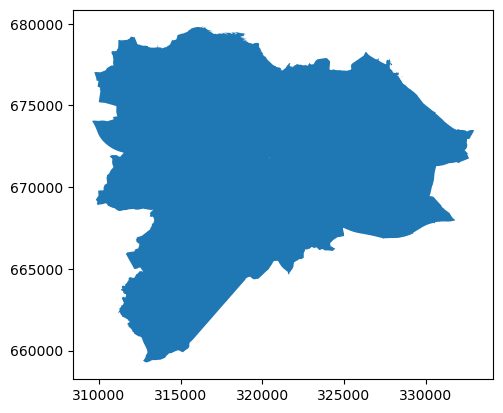

In [106]:
# Dissolve the gdf so it's just all of Edinburgh, not each council area
edi_boundary = edi_boundary_gdf.dissolve()
edi_boundary.plot() # Plot!!!

# 1. Air pollution
Files are from a pdf report produced by the City of Edinburgh Council
* Can just use AI to get them
* There is also this python method (not sure can install necessary library here though...).

Have zipped file wih all A tables from appendix

In [2]:
# Load in pollution tables from folder
pollution_tables = {}
pollution_path = os.path.join(base, 'data/raw/pollution')

for file in os.listdir(pollution_path):

    filepath = os.path.join(pollution_path, file)
    df = pd.read_csv(filepath)

    pollution_tables[file] = df


for name in pollution_tables:
    print(name)

A02_nonautomatic_sites.csv
A04_annual_NO2_diffusion_tubes.csv
A08_NO2_AQMA_trends.csv
A06_NO2_AQMA_trends.csv
A07_NO2_AQMA_trends.csv
A09_NO2_AQMA_trends.csv


In [3]:
pollution_tables['A02_nonautomatic_sites.csv'].head()

,site_id,site_name,site_type,easting,northing,pollutants_monitored,aqma_status,distance_to_exposure_m,distance_to_kerb_m,colocated_continuous_analyser,tube_height_m
0,13a,Deanhaugh Street,Roadside,324533,674655,NO2,No,0.0,2.0,No,2.0
1,16,Glasgow Road 68/adj,Roadside,313028,672633,NO2,Yes - Glasgow Road,4.4,1.8,No,2.0
2,15a,Glasgow Road Facade/9,Roadside,312711,672674,NO2,Yes - Glasgow Road,0.0,7.5,No,2.0
3,"58i, 58ii",Glasgow Rd Newbridge,Roadside,312693,672670,NO2,Yes - Glasgow Road,5.2,2.8,No,2.0
4,15,Glasgow Rd Newbridge,Roadside,312664,672672,NO2,Yes - Glasgow Road,3.8,4.0,No,2.0


In [14]:
pollution_tables['A09_NO2_AQMA_trends.csv']

,site_id,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,1b,48.8,44.2,43.5,38.4,44.0,41.0,37.0,33.0,36.1,28.5,27.7,27.3,17.4,20.8,19.2,19.5,18.9
1,1d,84.9,57.8,58.8,56.3,52.0,52.0,48.0,46.0,45.1,42.0,40.1,37.7,28.8,29.1,29.3,28.5,28.2
2,39,31.7,28.2,31.1,30.0,32.0,35.0,32.0,30.0,30.0,30.0,32.0,30.4,19.1,21.6,21.0,18.9,20.7
3,Mean,55.1,43.4,44.5,41.6,42.7,42.7,39.0,36.3,37.1,33.5,33.3,31.8,21.8,23.8,23.1,22.3,22.6


In [16]:
out_path = Path(base, 'data/processed/pollution_csvs')
out_path.mkdir(parents=True, exist_ok=True)

# clean hidden values
for table, df in pollution_tables.items():

    # Also need to change year columns to YEAR_2020 because oracle has trouble with number column names?
    df = df.rename(columns={str(year): f"year_{year}" for year in range (2000,2025)})

    # later might want to do mkdir so dont have to manually make table
    df.columns = df.columns.str.replace("\ufeff", "", regex=False)

    # Replace - with actual null values to can put into sql
    df = df.replace("-", pd.NA)

    print(table, df.columns)                                  
    
    processed_pollution_path = os.path.join(out_path, table)

    df.to_csv(processed_pollution_path, index=False, encoding="utf-8")
  

A02_nonautomatic_sites.csv Index(['site_id', 'site_name', 'site_type', 'easting', 'northing',
       'pollutants_monitored', 'aqma_status', 'distance_to_exposure_m',
       'distance_to_kerb_m', 'colocated_continuous_analyser', 'tube_height_m'],
      dtype='object')
A04_annual_NO2_diffusion_tubes.csv Index(['site_id_and_name', 'easting', 'northing', 'site_type',
       'capture_monitoring_period_pct', 'capture_2024_pct', 'year_2020',
       'year_2021', 'year_2022', 'year_2023', 'year_2024'],
      dtype='object')
A08_NO2_AQMA_trends.csv Index(['site_id', 'year_2008', 'year_2009', 'year_2010', 'year_2011',
       'year_2012', 'year_2013', 'year_2014', 'year_2015', 'year_2016',
       'year_2017', 'year_2018', 'year_2019', 'year_2020', 'year_2021',
       'year_2022', 'year_2023', 'year_2024'],
      dtype='object')
A06_NO2_AQMA_trends.csv Index(['site_id', 'year_2008', 'year_2009', 'year_2010', 'year_2011',
       'year_2012', 'year_2013', 'year_2014', 'year_2015', 'year_2016',
      

In [119]:
pollution_tables['A04_annual_NO2_diffusion_tubes.csv'].dtypes

site_id_and_name                  object
easting                            int64
northing                           int64
site_type                         object
capture_monitoring_period_pct    float64
capture_2024_pct                 float64
2020                             float64
2021                             float64
2022                             float64
2023                             float64
2024                              object
dtype: object

### JOIN!

In [120]:
# Join sites data to NO2 pollution table - just these to start
# A02_nonautomatic_sites.csv
# A04_annual_NO2_diffusion_tubes.cs

sensor_sites_df = pollution_tables['A02_nonautomatic_sites.csv']
no2_data_df = pollution_tables['A04_annual_NO2_diffusion_tubes.csv']
no2_data_df.rename(columns={'site_id_and_name':'site_id'}, inplace=True)


no2_site_data = sensor_sites_df.merge(no2_data_df, on=['site_id', 'easting', 'northing', 'site_type'], how='outer')
no2_site_data


,site_id,site_name,site_type,easting,northing,pollutants_monitored,aqma_status,distance_to_exposure_m,distance_to_kerb_m,colocated_continuous_analyser,tube_height_m,capture_monitoring_period_pct,capture_2024_pct,2020,2021,2022,2023,2024
0,13a,Deanhaugh Street,Roadside,324533,674655,NO2,No,0.0,2.0,No,2.0,92.5,92.5,15.4,16.3,15.7,15.6,14.5
1,16,Glasgow Road 68/adj,Roadside,313028,672633,NO2,Yes - Glasgow Road,4.4,1.8,No,2.0,100.0,100.0,26.7,27.9,27.7,32.0,27.4
2,15a,Glasgow Road Facade/9,Roadside,312711,672674,NO2,Yes - Glasgow Road,0.0,7.5,No,2.0,100.0,100.0,17.3,21.5,25.3,26.0,19.8
3,"58i, 58ii",Glasgow Rd Newbridge,Roadside,312693,672670,NO2,Yes - Glasgow Road,5.2,2.8,No,2.0,100.0,100.0,29.2,30.7,34.8,31.2,27.1
4,15,Glasgow Rd Newbridge,Roadside,312664,672672,NO2,Yes - Glasgow Road,3.8,4.0,No,2.0,100.0,100.0,24.3,26.6,31.8,27.7,23.9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123,"CL7, CL8, CL9",Salamander Street,Roadside,327616,676343,NO2,No,0.0,2.1,Yes,2.4,100.0,100.0,20.7,20.7,19.2,17.6,15.2
124,"CL13, CL14, CL15",St Johns Road,Kerbside,320101,672907,NO2,Yes - St John's Road,0.0,0.5,Yes,1.8,100.0,100.0,25.9,27.2,28.9,27.7,29.1
125,"CL16, CL17, CL18",Nicolson Street,Roadside,326151,673041,NO2,Yes - City Centre,2.2,2.9,Yes,1.8,100.0,100.0,30.3,26.7,23.2,25.4,21.9
126,"CL19, CL20, CL21",Drumsheugh,Roadside,324407,673843,NO2,No,0.0,1.0,Yes,2.0,100.0,100.0,NaN,NaN,NaN,NaN,17.8


<AxesSubplot: >

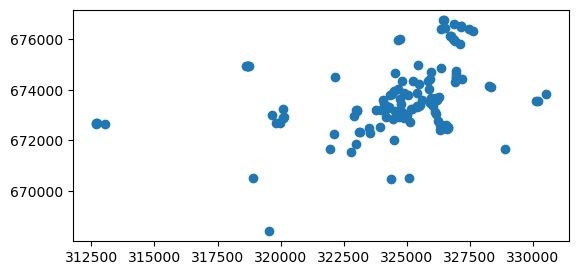

In [121]:
# Turn into gdfs

# Clean up a little first
no2_site_data.drop(columns=['pollutants_monitored'], inplace=True)

no2_site_data_gdf =  gpd.GeoDataFrame(no2_site_data,
    geometry=gpd.points_from_xy(no2_site_data['easting'], no2_site_data['northing']),
    crs="EPSG:27700")

no2_site_data_gdf.plot()


In [122]:
# Save to shapefile!!!
output_dir = Path(base, "data/processed/annual_no2")
output_dir.mkdir(parents=True, exist_ok=True)

no2_site_data_gdf.to_file(output_dir / "annual_no2.shp")

/tmp/ipykernel_2872571/727853931.py:5: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  no2_site_data_gdf.to_file(output_dir / "annual_no2.shp")


# 2. Greenspaces - Council Trees

In [126]:
# Read in council trees data (already in csv from)
tree_raw_path = os.path.join(base, 'data/raw/Trees.csv')
trees = pd.read_csv(tree_raw_path, encoding="utf-8")
print(trees.shape)
trees.head()

(50400, 17)


,X,Y,OBJECTID,PrimaryKey,LocationOrTagNo,Ward,Site,LatinName,CommonName,Owner,NTRef,Height,Spread,AgeGroup,DiameterAtBreastHeight,Easting,Northing
0,309001,660993,1,Grp/1 (845800),NaN,Inverleith\n,"Raeburn Mews, Edinburgh",NaN,NaN,NaN,NT06-9001-0993,NaN,NaN,Over-Mature,NaN,309001,660993
1,309010,661010,2,Sgl/358 (813204),2-205-16,Fountainbridge/Craiglockhart\n,Craiglockhart Woods,NaN,NaN,Culture and Leisure,NT06-9010-1010,5 to 10 meters,6 to 9 meters,Juvenile,10 - 20,309010,661010
2,310000,674261,3,Sgl/18 (046468),b05936,Drum Brae/Gyle\n,"Rannoch Road, Edinburgh",Acer pseudoplatanus,Sycamore,NaN,NT17-0000-4261,15 to 20 meters,Over 12 meters,Mature,90 +,310000,674261
3,310000,675419,4,Sgl/1274 (071816),g00495,Almond\n,Davidson's Main's Park,Acer pseudoplatanus,Sycamore,Culture and Leisure,NT17-0000-5419,20 to 25 meters,Over 12 meters,Mature,90 +,310000,675419
4,310000,675184,5,Sgl/82 (193348),w765,Almond\n,Royal High School,Acer pseudoplatanus,Sycamore,Children and Families,NT17-0000-5184,15 to 20 meters,9 to 12 meters,Mature,50 - 60,310000,675184


In [124]:
trees.columns

Index(['X', 'Y', 'OBJECTID', 'PrimaryKey', 'LocationOrTagNo', 'Ward', 'Site',
       'LatinName', 'CommonName', 'Owner', 'NTRef', 'Height', 'Spread',
       'AgeGroup', 'DiameterAtBreastHeight', 'Easting', 'Northing'],
      dtype='object')

In [128]:
# Save to csv
trees.columns = trees.columns.str.replace("\ufeff", "", regex=False)

trees_processed_path = os.path.join(base, 'data/processed/Trees.csv')
trees.to_csv(trees_processed_path, index=False, encoding="utf-8")

# 3. Greenspaces - OS Greenspaces

In [141]:
# Read in Ordinance Survey greenspaces data - shapefile
os_green_raw_path = os.path.join(base, 'data/raw/opgrsp_essh_nt/OS Open Greenspace (ESRI Shape File) NT/data/NT_GreenspaceSite.shp')
os_green = gpd.read_file(os_green_raw_path)
os_green.head()

,id,function,distName1,distName2,distName3,distName4,geometry
0,49E9C86F-EAA3-A491-E063-8CCAA00A0EF3,Playing Field,Old Shielfield Park,None,None,None,"POLYGON Z ((399186.650 651820.290 0.000, 39918..."
1,49E9C77A-3F44-A491-E063-8CCAA00A0EF3,Cemetery,None,None,None,None,"POLYGON Z ((399424.640 654073.090 0.000, 39942..."
2,49E9C86A-1CA7-A491-E063-8CCAA00A0EF3,Play Space,None,None,None,None,"POLYGON Z ((399276.390 654844.900 0.000, 39925..."
3,49E9C6F6-402B-A491-E063-8CCAA00A0EF3,Allotments Or Community Growing Spaces,None,None,None,None,"POLYGON Z ((399307.760 652907.720 0.000, 39928..."
4,49E9C701-7236-A491-E063-8CCAA00A0EF3,Bowling Green,None,None,None,None,"POLYGON Z ((399329.280 652970.890 0.000, 39935..."


(962, 7)


<AxesSubplot: >

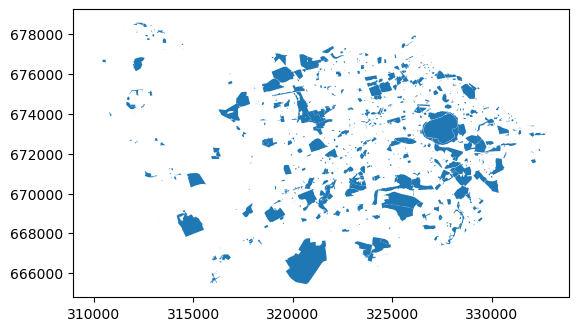

In [143]:
# Clip os_green to Edinburgh city boundary
os_green_edi = os_green.clip(edi_boundary)
print(os_green_edi.shape)
os_green_edi.plot()

In [133]:
os_green_edi['function'].unique()

array(['Public Park Or Garden', 'Play Space', 'Bowling Green',
       'Allotments Or Community Growing Spaces', 'Other Sports Facility',
       'Playing Field', 'Cemetery', 'Tennis Court', 'Golf Course',
       'Religious Grounds'], dtype=object)

In [144]:
#Drop unneccesary columns
os_green_edi.drop(columns=['distName3', 'distName4'], inplace=True)

# Remove any hidden characters frm column
os_green_edi.columns = os_green_edi.columns.str.replace("\ufeff", "", regex=False)

# Need to change geometry for ordinance survey shapefiles so can upload to sql db 
os_green_edi_for_csv = os_green_edi.copy()

os_green_edi_for_csv["geometry_wkt"] = os_green_edi_for_csv.geometry.to_wkt()
os_green_edi_for_csv = os_green_edi_for_csv.drop(columns="geometry")

# Save to CSV!
output_path = os.path.join(base, 'data/processed/os_green_edi.csv')
os_green_edi_for_csv.to_csv(output_path, index=False, encoding="utf-8")

In [431]:
# Save as shapefile
output_dir = Path("data_shp/os_green_edi")
output_dir.mkdir(parents=True, exist_ok=True)

os_green_edi.to_file(output_dir / "os_green_edi.shp")

# 4. Traffic + OS Road

In [145]:
# Read in Annual Average Daily Flow data from DfT (already in csv form)
traffic_raw_path = os.path.join(base, 'data/raw/dft_aadf_local_authority_id_29.csv')
traffic = pd.read_csv(traffic_raw_path)
print(traffic.shape)
traffic.head(3)

(2709, 31)


,count_point_id,year,region_id,region_name,local_authority_id,local_authority_name,road_name,road_type,start_junction_road_name,end_junction_road_name,...,buses_and_coaches,lgvs,hgvs_2_rigid_axle,hgvs_3_rigid_axle,hgvs_4_or_more_rigid_axle,hgvs_3_or_4_articulated_axle,hgvs_5_articulated_axle,hgvs_6_articulated_axle,all_hgvs,all_motor_vehicles
0,703,2000,3,Scotland,29,City of Edinburgh,M9,Major,1,A8000,...,96,1794,531,121,117,288,534,559,2150,15811
1,703,2001,3,Scotland,29,City of Edinburgh,M9,Major,1,A8000,...,98,1896,542,145,122,263,476,651,2199,16314
2,703,2002,3,Scotland,29,City of Edinburgh,M9,Major,1,A8000,...,98,2037,554,160,135,248,429,741,2267,16676


In [146]:
print(traffic['year'].unique())
traffic.columns

[2000 2001 2002 2003 2004 2005 2006 2007 2008 2009 2010 2011 2012 2013
 2014 2015 2016 2017 2018 2019 2020 2021 2022 2023 2024 2025]


Index(['count_point_id', 'year', 'region_id', 'region_name',
       'local_authority_id', 'local_authority_name', 'road_name', 'road_type',
       'start_junction_road_name', 'end_junction_road_name', 'easting',
       'northing', 'latitude', 'longitude', 'link_length_km',
       'link_length_miles', 'estimation_method', 'estimation_method_detailed',
       'pedal_cycles', 'two_wheeled_motor_vehicles', 'cars_and_taxis',
       'buses_and_coaches', 'lgvs', 'hgvs_2_rigid_axle', 'hgvs_3_rigid_axle',
       'hgvs_4_or_more_rigid_axle', 'hgvs_3_or_4_articulated_axle',
       'hgvs_5_articulated_axle', 'hgvs_6_articulated_axle', 'all_hgvs',
       'all_motor_vehicles'],
      dtype='object')

In [147]:
drop_years = []
for i in range(2000,2021):
    drop_years.append(i)

traffic2 = traffic[~traffic['year'].isin(drop_years)]
print(traffic2['year'].unique())

[2021 2022 2023 2024 2025]


In [148]:
traffic_wide = traffic2.pivot_table(
    index=['count_point_id', 'road_name', 'road_type', 'start_junction_road_name', 'end_junction_road_name', 'easting', 'northing', 'latitude', 'longitude', 'link_length_km'],
    columns="year",
    values="all_motor_vehicles",
).reset_index()

traffic_wide

year,count_point_id,road_name,road_type,start_junction_road_name,end_junction_road_name,easting,northing,latitude,longitude,link_length_km,2021,2022,2023,2024,2025
0,1006,A1,Major,A6106,A1140,330021,672785,55.942989,-3.121961,2.6,11507.0,12308.0,12519.0,12700.0,12741.0
1,1012,A8,Major,A902,B701,319000,672860,55.941929,-3.298381,1.3,21386.0,22876.0,23281.0,23631.0,23699.0
2,1015,A70,Major,B701,A71,322750,671600,55.931230,-3.238000,4.6,11797.0,12629.0,12854.0,13053.0,13106.0
3,1150,A901,Major,A199,A902,326485,676600,55.976729,-3.179601,0.3,NaN,NaN,NaN,9357.0,9397.0
4,1150,A901,Major,A199,A902,326500,676600,55.976732,-3.179361,0.3,7720.0,8257.0,8389.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102,94256,M8,Major,2,1,312642,671382,55.927540,-3.399659,1.4,NaN,34494.0,35359.0,37054.0,33063.0
103,94257,M8,Major,2,3,312602,672150,55.934431,-3.400547,1.4,NaN,68989.0,70718.0,73969.0,75243.0
104,95012,A900,Major,Junction A1/A900/A8,Junction A901/A900,326480,675000,55.962356,-3.179244,2.5,NaN,NaN,15646.0,NaN,NaN
105,95012,A900,Major,Junction A1/A900/A8,Junction A901/A900,326401,674907,55.961509,-3.180483,2.5,NaN,NaN,NaN,5886.0,5903.0


In [149]:
traffic_clean = traffic_wide[~traffic_wide['start_junction_road_name'].isnull()]
traffic_clean

year,count_point_id,road_name,road_type,start_junction_road_name,end_junction_road_name,easting,northing,latitude,longitude,link_length_km,2021,2022,2023,2024,2025
0,1006,A1,Major,A6106,A1140,330021,672785,55.942989,-3.121961,2.6,11507.0,12308.0,12519.0,12700.0,12741.0
1,1012,A8,Major,A902,B701,319000,672860,55.941929,-3.298381,1.3,21386.0,22876.0,23281.0,23631.0,23699.0
2,1015,A70,Major,B701,A71,322750,671600,55.931230,-3.238000,4.6,11797.0,12629.0,12854.0,13053.0,13106.0
3,1150,A901,Major,A199,A902,326485,676600,55.976729,-3.179601,0.3,NaN,NaN,NaN,9357.0,9397.0
4,1150,A901,Major,A199,A902,326500,676600,55.976732,-3.179361,0.3,7720.0,8257.0,8389.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102,94256,M8,Major,2,1,312642,671382,55.927540,-3.399659,1.4,NaN,34494.0,35359.0,37054.0,33063.0
103,94257,M8,Major,2,3,312602,672150,55.934431,-3.400547,1.4,NaN,68989.0,70718.0,73969.0,75243.0
104,95012,A900,Major,Junction A1/A900/A8,Junction A901/A900,326480,675000,55.962356,-3.179244,2.5,NaN,NaN,15646.0,NaN,NaN
105,95012,A900,Major,Junction A1/A900/A8,Junction A901/A900,326401,674907,55.961509,-3.180483,2.5,NaN,NaN,NaN,5886.0,5903.0


In [49]:
traffic_clean.dtypes

year
count_point_id                int64
road_name                    object
road_type                    object
start_junction_road_name     object
end_junction_road_name       object
easting                       int64
northing                      int64
latitude                    float64
longitude                   float64
link_length_km              float64
2021                        float64
2022                        float64
2023                        float64
2024                        float64
2025                        float64
dtype: object

In [150]:
# Create GeoDataFrame
traffic_clean_gdf = gpd.GeoDataFrame(traffic_clean,
    geometry=gpd.points_from_xy(
        traffic_clean["easting"],
        traffic_clean["northing"]
    ),
    crs="EPSG:27700"
)

## Clean OS Road

In [151]:
# Read in Ordinance Survey road data - shapefile
os_road_path = os.path.join(base, 'data/raw/osroad_nt/NT_RoadLink.shp')
os_road = gpd.read_file(os_road_path)
os_road.head(3)

,fictitious,identifier,class,roadNumber,name1,name1_lang,name2,name2_lang,formOfWay,length,primary,trunkRoad,loop,startNode,endNode,structure,nameTOID,numberTOID,function,geometry
0,false,6E995E9A-242D-423A-BE78-7C841D71DC0B,B Road,B9130,Blackwood Road,None,None,None,Single Carriageway,398,false,false,false,482138F6-A79D-4113-84A1-C73C2EDF62AB,74F14F66-95F5-4F99-9491-E61D4BE1A4AE,None,osgb4000000004511201,osgb4000000006307054,B Road,"LINESTRING (329348.800 698755.600, 329323.600 ..."
1,false,4A530213-CC87-43FC-82D9-8257E90C2B7A,B Road,B921,None,None,None,None,Roundabout,23,false,false,false,03E8CBE7-9BDA-4013-BD33-7CB8CED78894,D97C71A8-9125-487F-8C2D-1817C63EADEC,None,None,osgb4000000006307036,B Road,"LINESTRING (329060.000 699489.000, 329064.000 ..."
2,false,356203F8-888E-424A-B60A-6998C942ECFC,Unknown,None,None,None,None,None,Single Carriageway,232,false,false,false,02462254-5AE0-4B83-8363-D778BA73E0E0,37C38F73-6B8D-45B4-881A-04E06F94FD13,None,None,None,Restricted Local Access Road,"LINESTRING (329064.650 699458.300, 329076.720 ..."


(19620, 20)
Index(['fictitious', 'identifier', 'class', 'roadNumber', 'name1',
       'name1_lang', 'name2', 'name2_lang', 'formOfWay', 'length', 'primary',
       'trunkRoad', 'loop', 'startNode', 'endNode', 'structure', 'nameTOID',
       'numberTOID', 'function', 'geometry'],
      dtype='object')


<AxesSubplot: >

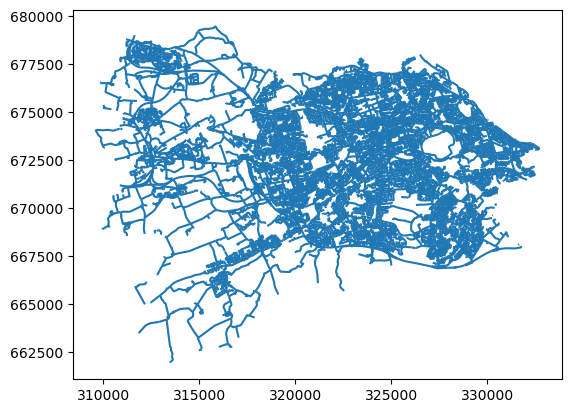

In [152]:
# Clip os_green to Edinburgh city boundary
os_road_edi = os_road.clip(edi_boundary)

print(os_road_edi.shape)
print(os_road_edi.columns)
os_road_edi.plot()

In [153]:
os_road_drop = os_road_edi.columns[os_road_edi.isna().all()].tolist()
print(os_road_drop)

os_road_edi["class"].value_counts()

['name1_lang', 'name2', 'name2_lang']


class
Unclassified             11544
Unknown                   3654
Not Classified            1473
A Road                    1459
Classified Unnumbered      941
B Road                     498
Motorway                    51
Name: count, dtype: int64

### Fill in missing roads - just princes street

In [154]:
# Reclassify unnamed Princes Street segments as A8
mask = (
    (os_road_edi["name1"] == "Princes Street") &
    (os_road_edi["class"] == "Unknown"))

os_road_edi.loc[mask, "class"] = "A8"
os_road_edi.loc[mask, "roadNumber"] = "A8"

# Remove unwanted road classes
drop_classes = [
    "Unknown",
    "Not Classified",
    "Unclassified",
    "B Road",
    "Classified Unnumbered"]

os_road_edi = os_road_edi[
    ~os_road_edi["class"].isin(drop_classes)].copy()

print(os_road_edi.shape)

(1520, 20)


In [155]:
os_road_edi[
    os_road_edi["name1"] == "Princes Street"
][["name1", "class", "roadNumber"]]

,name1,class,roadNumber
24496,Princes Street,A8,A8
23946,Princes Street,A8,A8
24362,Princes Street,A8,A8
24365,Princes Street,A8,A8
24066,Princes Street,A8,A8
24082,Princes Street,A8,A8
24001,Princes Street,A8,A8
24003,Princes Street,A8,A8
23942,Princes Street,A8,A8
23945,Princes Street,A8,A8


<AxesSubplot: >

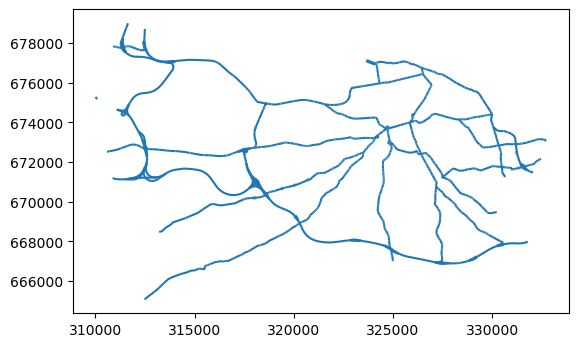

In [156]:
os_road_edi.plot()

In [157]:
os_road_edi_clean = os_road_edi.drop(columns=['name1_lang', 'name2', 'name2_lang', 'formOfWay', 'fictitious', 
                                              'primary', 'trunkRoad', 'loop', 'structure', 'nameTOID', 'numberTOID', 'function'])
print(os_road_edi_clean.shape)
os_road_edi_clean.head(3)

(1520, 8)


,identifier,class,roadNumber,name1,length,startNode,endNode,geometry
43185,F6ED85D6-E978-4F12-801C-7AB0B791D979,A Road,A70,Lanark Road West,94,79896C1A-F0D5-4C4C-8BCC-B68C3B7A3770,92F276B4-5CFB-4EF8-8D25-4E63BB956E87,"LINESTRING (317709.000 667497.000, 317749.450 ..."
43096,C5370E2C-0B53-4707-9EF2-5167C3D63AE3,A Road,A70,Lanark Road West,341,92F276B4-5CFB-4EF8-8D25-4E63BB956E87,A55DFAF2-84CA-48CE-B308-22476BACA05C,"LINESTRING (317789.910 667545.160, 317804.590 ..."
42966,9B6CFB28-879B-4CDD-8CD1-8BED5B9D8EC0,A Road,A70,Lanark Road West,17,37A7F950-5235-4A73-9909-3AA341133C71,41629D94-9E3F-4730-A10D-64CA7A163A3D,"LINESTRING (318326.000 667813.000, 318334.000 ..."


In [158]:
# Remove any hidden characters frm column
os_road_edi_clean.columns = os_road_edi_clean.columns.str.replace("\ufeff", "", regex=False)

In [159]:
os_road_edi_clean.dtypes

identifier      object
class           object
roadNumber      object
name1           object
length           int64
startNode       object
endNode         object
geometry      geometry
dtype: object

## JOIN traffic and road

In [89]:
roads = os_road_edi_clean.to_crs(27700).copy()
traffic = traffic_clean_gdf.copy()

# Filter to A-roads
roads = roads[
    roads["roadNumber"].str.startswith("A", na=False)].copy()

traffic = traffic[
    traffic["road_name"].str.startswith("A", na=False)].copy()

# Create points from easting/northing
traffic["geometry"] = [
    Point(x, y)
    for x, y in zip(traffic["easting"], traffic["northing"])
]

traffic = gpd.GeoDataFrame(
    traffic, geometry="geometry", crs=27700
)

In [67]:
print(roads.columns)
print(traffic.columns)

Index(['identifier', 'class', 'roadNumber', 'name1', 'length', 'startNode',
       'endNode', 'geometry'],
      dtype='object')
Index([          'count_point_id',                'road_name',
                      'road_type', 'start_junction_road_name',
         'end_junction_road_name',                  'easting',
                       'northing',                 'latitude',
                      'longitude',           'link_length_km',
                             2021,                       2022,
                             2023,                       2024,
                             2025,                 'geometry'],
      dtype='object', name='year')


In [90]:
def network_distances(graph, start, end, position, length):

    distances = {}

    heap = [
        (position, start),
        (length - position, end)
    ]

    heapq.heapify(heap)

    while heap:
        distance, node = heapq.heappop(heap)

        if distance >= distances.get(node, float("inf")):
            continue

        distances[node] = distance

        for neighbor, weight in graph[node]:
            new_distance = distance + weight

            if new_distance < distances.get(neighbor, float("inf")):
                heapq.heappush(
                    heap, (new_distance, neighbor)
                )

    return distances

In [91]:
assigned_roads = roads.copy()

for col in [
    "count_id", "aadf_21", "aadf_22", "aadf_23", "aadf_24", "aadf_25", 
    "assignment_distance", "snap_distance", "method"
]:
    assigned_roads[col] = None

for road_name, group in roads.groupby("roadNumber"):

    counts = traffic[
        traffic["road_name"] == road_name
    ]

    if counts.empty:
        continue

    # Build road network
    graph = defaultdict(list)

    for idx, road in group.iterrows():
        start = road["startNode"]
        end = road["endNode"]
        length = road.geometry.length

        graph[start].append((end, length))
        graph[end].append((start, length))

    # Snap each traffic point to nearest matching road
    candidates = []

    for _, count in counts.iterrows():

        point = count.geometry

        distances = group.geometry.distance(point)
        seed_idx = distances.idxmin()

        seed = group.loc[seed_idx]

        position = seed.geometry.project(point)
        snap_distance = seed.geometry.distance(point)

        network = network_distances(
            graph,
            seed["startNode"],
            seed["endNode"],
            position,
            seed.geometry.length
        )

        candidates.append(
            (count, network, snap_distance, seed_idx)
        )

    # Assign each road segment to nearest traffic count
    for idx, road in group.iterrows():

        options = []

        for count, network, snap, seed_idx in candidates:

            distance = min(
                network.get(road["startNode"], float("inf")),
                network.get(road["endNode"], float("inf"))
            ) + road.geometry.length / 2

            options.append(
                (distance, count, snap, seed_idx)
            )

        distance, count, snap, seed_idx = min(
            options, key=lambda x: x[0]
        )

        method = "network"

        # Fallback for disconnected road segments
        if not math.isfinite(distance):

            distance, count, snap, seed_idx = min(
                [
                    (
                        road.geometry.distance(c.geometry),
                        c, s, seed
                    )
                    for c, _, s, seed in candidates
                ],
                key=lambda x: x[0]
            )

            method = "euclidean_fallback"

        assigned_roads.at[idx, "count_id"] = count["count_point_id"]
        assigned_roads.at[idx, "aadf_21"] = count[2021]
        assigned_roads.at[idx, "aadf_22"] = count[2022]
        assigned_roads.at[idx, "aadf_23"] = count[2023]
        assigned_roads.at[idx, "aadf_24"] = count[2024]
        assigned_roads.at[idx, "aadf_25"] = count[2025]
        assigned_roads.at[idx, "assignment_distance"] = distance
        assigned_roads.at[idx, "snap_distance"] = snap
        assigned_roads.at[idx, "method"] = method

In [92]:
assigned_roads.head()

,identifier,class,roadNumber,name1,length,startNode,endNode,geometry,count_id,aadf_21,aadf_22,aadf_23,aadf_24,aadf_25,assignment_distance,snap_distance,method
43185,F6ED85D6-E978-4F12-801C-7AB0B791D979,A Road,A70,Lanark Road West,94,79896C1A-F0D5-4C4C-8BCC-B68C3B7A3770,92F276B4-5CFB-4EF8-8D25-4E63BB956E87,"LINESTRING (317709.000 667497.000, 317749.450 ...",30827,10547.0,10493.0,10681.0,10844.0,10882.0,169.531771,10.696564,network
43096,C5370E2C-0B53-4707-9EF2-5167C3D63AE3,A Road,A70,Lanark Road West,341,92F276B4-5CFB-4EF8-8D25-4E63BB956E87,A55DFAF2-84CA-48CE-B308-22476BACA05C,"LINESTRING (317789.910 667545.160, 317804.590 ...",30827,10547.0,10493.0,10681.0,10844.0,10882.0,293.112156,10.696564,network
42966,9B6CFB28-879B-4CDD-8CD1-8BED5B9D8EC0,A Road,A70,Lanark Road West,17,37A7F950-5235-4A73-9909-3AA341133C71,41629D94-9E3F-4730-A10D-64CA7A163A3D,"LINESTRING (318326.000 667813.000, 318334.000 ...",30827,10547.0,10493.0,10681.0,10844.0,10882.0,492.320522,10.696564,network
42967,863466B4-8F9D-473C-B105-2E3F032A905D,A Road,A70,Lanark Road West,239,41629D94-9E3F-4730-A10D-64CA7A163A3D,BD6C6247-C6D1-4922-AFDD-94ADC87AFBD4,"LINESTRING (318342.000 667818.000, 318381.640 ...",30827,10547.0,10493.0,10681.0,10844.0,10882.0,619.963942,10.696564,network
43101,24F3E983-125A-459F-B875-491C204C9C20,A Road,A70,Lanark Road West,215,A55DFAF2-84CA-48CE-B308-22476BACA05C,BC728E10-4C88-4031-AC23-B44FA0BD010A,"LINESTRING (318080.000 667725.000, 318101.850 ...",30827,10547.0,10493.0,10681.0,10844.0,10882.0,326.492997,10.696564,network


<AxesSubplot: >

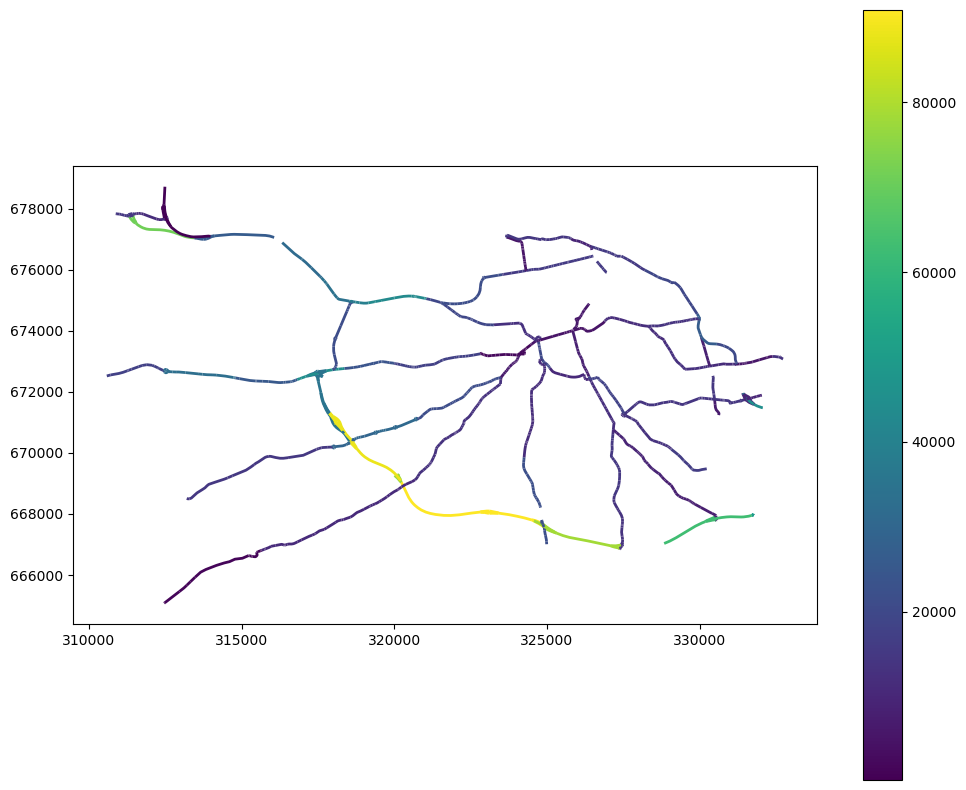

In [93]:
assigned_roads["aadf_21"] = pd.to_numeric(assigned_roads["aadf_21"], errors="coerce")
assigned_roads["aadf_22"] = pd.to_numeric(assigned_roads["aadf_22"], errors="coerce")
assigned_roads["aadf_23"] = pd.to_numeric(assigned_roads["aadf_23"], errors="coerce")
assigned_roads["aadf_24"] = pd.to_numeric(assigned_roads["aadf_24"], errors="coerce")
assigned_roads["aadf_25"] = pd.to_numeric(assigned_roads["aadf_25"], errors="coerce")

assigned_roads.plot(
    column="aadf_24",
    legend=True,
    linewidth=2,
    figsize=(12, 10)
)

In [ ]:
# Save as shapefile
output_dir = Path(base, "data/processed/traffic_correct")
output_dir.mkdir(parents=True, exist_ok=True)

assigned_roads.to_file(output_dir / "traffic_correct.shp")


/tmp/ipykernel_2872571/3966780330.py:5: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  assigned_roads.to_file(output_dir / "traffic_correct.shp")


In [162]:
assigned_roads.dtypes

identifier               object
class                    object
roadNumber               object
name1                    object
length                    int64
startNode                object
endNode                  object
geometry               geometry
count_id                 object
aadf_21                 float64
aadf_22                 float64
aadf_23                 float64
aadf_24                 float64
aadf_25                 float64
assignment_distance      object
snap_distance            object
method                   object
dtype: object